In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import keras
os.environ["KERAS_BACKEND"] = "jax"
import bayesflow as bf


INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)
INFO:bayesflow:Using backend 'jax'
/Users/dmahima/Documents/Data Science/sbi/SBI_Project/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
def fixed_boundary(t,a):
    """Constant boundary at value a."""
    return np.full_like(t, a)


def linear_collapse(t,a,k,epsilon=1e-4):
    """
    Linearly collapsing boundary.
    B(t) = max(a - k*t, epsilon)
    """
    return np.maximum(a - k * t, epsilon)


def exponential_collapse(t, a, lam, epsilon=1e-4):
    """
    Exponentially collapsing boundary.
    B(t) = a * exp(-lambda * t)
    
    Parameters
    ----------
    lam : float
        Decay rate (lambda). Larger = faster collapse.
    """
    return np.maximum(a * np.exp(-lam * t), epsilon)


def sigmoid_collapse( t , a, k_sig, t_mid) :
    """
    Sigmoid (logistic) collapsing boundary.
    B(t) = a * (1 - sigmoid(k * (t - t_mid)))
    
    Parameters
    ----------
    k_sig  : float  Steepness of collapse (larger = sharper)
    t_mid  : float  Time of inflection point
    """
    sig = 1.0 / (1.0 + np.exp(-k_sig * (t - t_mid)))
    return np.maximum(a * (1.0 - sig), 1e-4)


In [6]:

BOUNDARY_FNS = {
    "fixed": fixed_boundary,
    "linear": linear_collapse,
    "exponential": exponential_collapse,
    "sigmoid": sigmoid_collapse,
}

# Which shape-parameters each model needs, and their prior ranges.
# (v_scale, t0, a, sv are shared across all models.)
SHAPE_PRIOR_RANGES = {
    "fixed":       {},
    "linear":      {"k":     (0.1, 3.0)},
    "exponential": {"lam":   (0.05, 3.0)},
    "sigmoid":     {"k_sig": (0.5, 10.0), "t_mid": (0.2, 1.5)},
}


In [7]:

def sample_cell_priors(rng, model="exponential"):
    """
    Priors for ONE (participant x cue x deadline) cell, generalized
    to any boundary model. No hard-coded condition effects.
    """
    params = {
        "v_scale": rng.normal(8.0, 2.0),                  # coherence -> drift slope
        "t0":      rng.uniform(0.15, 0.40),                # non-decision time
        "a":       np.abs(rng.normal(1.0, 0.3)) + 0.2,     # initial boundary sep.
        "sv":      np.abs(rng.normal(0.15, 0.1)) + 0.01,   # trial-to-trial drift SD
    }
    for name, (lo, hi) in SHAPE_PRIOR_RANGES[model].items():
        params[name] = rng.uniform(lo, hi)
    return params



In [8]:

def simulate_ddm_batch(v, a, t0, z, sv, boundary, dt, n_trials, deadline_step, noise_sd, rng):
    """
    Vectorized Euler-Maruyama DDM simulation for n_trials of ONE cell.
    `boundary` is a precomputed time series (shape: max_steps,).
    `v` may be scalar or per-trial array (drift variability handled by
    sampling v_trial ~ Normal(v, sv) once, outside the time loop).

    Returns
    -------
    rts     : (n_trials,) seconds, NaN = non-response
    choices : (n_trials,) 1=upper/correct, 0=lower/error, -1=non-response
    """
    v_trial = rng.normal(v, sv, n_trials) if sv > 0 else np.full(n_trials, v)

    x = np.full(n_trials, (z - 0.5) * 2 * a, dtype=float)
    rts = np.full(n_trials, np.nan)
    choices = np.full(n_trials, -1, dtype=int)
    active = np.ones(n_trials, dtype=bool)
    max_steps = len(boundary) if deadline_step is None else min(len(boundary), deadline_step)

    for step in range(max_steps):
        if not active.any():
            break
        b = boundary[step]
        upper_hit = active & (x >= b)
        lower_hit = active & (x <= -b)

        rts[upper_hit] = t0 + step * dt
        choices[upper_hit] = 1
        rts[lower_hit] = t0 + step * dt
        choices[lower_hit] = 0
        active &= ~(upper_hit | lower_hit)

        x[active] += v_trial[active] * dt + noise_sd * np.sqrt(dt) * rng.standard_normal(active.sum())

    return rts, choices

In [9]:



def simulate_cell(params, model, coherences, n_trials_per_diff, dt, max_time,
                   deadline_time, z=0.5, noise_sd=1.0, rng=None):
    """Simulate all coherence levels for one cell using a given boundary model."""
    if rng is None:
        rng = np.random.default_rng()

    boundary_fn = BOUNDARY_FNS[model]
    time_axis = np.arange(int(max_time / dt)) * dt
    boundary = boundary_fn(time_axis, a=params["a"], **{k: params[k] for k in SHAPE_PRIOR_RANGES[model]})
    deadline_step = int(deadline_time / dt) if deadline_time is not None else None

    rts_all, choices_all, diff_all = [], [], []
    for diff_idx, coherence in enumerate(coherences, start=1):
        v = params["v_scale"] * coherence
        rts, choices = simulate_ddm_batch(
            v=v, a=params["a"], t0=params["t0"], z=z, sv=params["sv"],
            boundary=boundary, dt=dt, n_trials=n_trials_per_diff,
            deadline_step=deadline_step, noise_sd=noise_sd, rng=rng,
        )
        rts_all.append(rts); choices_all.append(choices)
        diff_all.append(np.full(n_trials_per_diff, coherence))

    return (np.concatenate(rts_all), np.concatenate(choices_all), np.concatenate(diff_all))



In [10]:

def simulate_full_dataset(
    model="exponential",
    n_participants=24,
    coherences=(0.03, 0.07, 0.11, 0.15, 0.19, 0.23),
    cues=("speed", "accuracy"),
    deadline_conditions=("deadline", "no_deadline"),
    n_trials_per_cell=50,
    dt=0.002,
    deadline_time=1.35,
    max_time=3.0,
    noise_sd=1.0,
    seed=0,
):
    rng = np.random.default_rng(seed)
    rows, true_params = [], []

    for pp in range(1, n_participants + 1):
        for cue in cues:
            for deadline_cond in deadline_conditions:
                p = sample_cell_priors(rng, model=model)
                ddl = deadline_time if deadline_cond == "deadline" else None

                rts, choices, coh = simulate_cell(
                    p, model, coherences, n_trials_per_cell, dt, max_time, ddl,
                    noise_sd=noise_sd, rng=rng,
                )
                for rt, ch, c in zip(rts, choices, coh):
                    rows.append({
                        "rt": rt, "acc": np.nan if ch == -1 else int(ch == 1),
                        "pp": pp, "deadline": deadline_cond, "cue": cue, "coherence": c,
                    })
                true_params.append({"pp": pp, "cue": cue, "deadline": deadline_cond, **p})

    return pd.DataFrame(rows), pd.DataFrame(true_params)

In [11]:
MODEL_NAMES = ["fixed", "linear", "exponential", "sigmoid"]

DT = 0.002
MAX_TIME = 3.0
COHERENCES = (0.03, 0.07, 0.11, 0.15, 0.19, 0.23)
N_TRIALS_PER_DIFF = 20          # -> 120 trials per simulated "cell"
DEADLINE_TIME = 1.35


def prior():
    """Samples model identity + all latent DDM parameters for one cell."""
    rng = np.random.default_rng()
    model_idx = rng.integers(0, len(MODEL_NAMES))
    model = MODEL_NAMES[model_idx]
    p = sample_cell_priors(rng, model=model)
    return {
        "model_idx": model_idx,
        "v_scale": p["v_scale"], "t0": p["t0"], "a": p["a"], "sv": p["sv"],
        "k":     p.get("k", 0.0),
        "lam":   p.get("lam", 0.0),
        "k_sig": p.get("k_sig", 0.0),
        "t_mid": p.get("t_mid", 0.0),
    }


def likelihood(model_idx, v_scale, t0, a, sv, k, lam, k_sig, t_mid):
    """Simulate one cell's (rt, choice, coherence) trials, sampling deadline presence internally."""
    rng = np.random.default_rng()
    model = MODEL_NAMES[model_idx]
    shape_params = {"linear": {"k": k}, "exponential": {"lam": lam},
                    "sigmoid": {"k_sig": k_sig, "t_mid": t_mid}, "fixed": {}}[model]
    params = {"v_scale": v_scale, "t0": t0, "a": a, "sv": sv, **shape_params}

    has_deadline = rng.integers(0, 2)
    ddl = DEADLINE_TIME if has_deadline else None
    rts, choices, coh = simulate_cell(
        params, model, COHERENCES, N_TRIALS_PER_DIFF, DT, MAX_TIME, ddl, rng=rng
    )
    rts_clean = np.where(choices == -1, -1.0, rts)
    return {
        "has_deadline": has_deadline,
        "rt": rts_clean.astype("float32"),
        "choice": choices.astype("float32"),
        "coherence": coh.astype("float32"),
    }




In [ ]:
simulator = bf.make_simulator([prior, likelihood])

sample = simulator.sample(batch_shape=(8,))
for k, v in sample.items():
    print(k, np.asarray(v).shape)

model_idx (8, 1)
v_scale (8, 1)
t0 (8, 1)
a (8, 1)
sv (8, 1)
k (8, 1)
lam (8, 1)
k_sig (8, 1)
t_mid (8, 1)
has_deadline (8, 1)
rt (8, 120)
choice (8, 120)
coherence (8, 120)


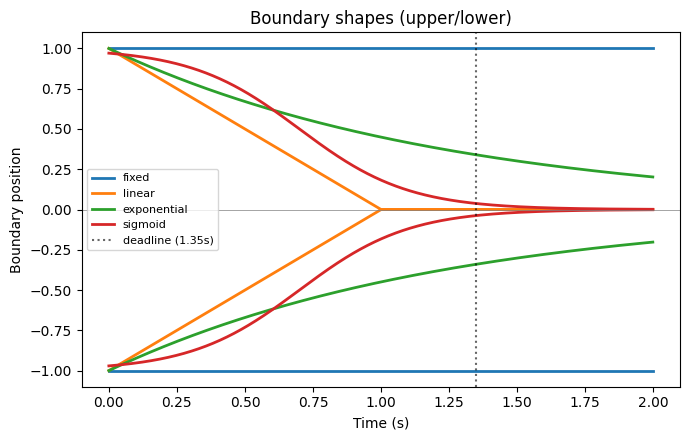

In [ ]:

def plot_boundary_shapes(a=1.0, k=1.0, lam=0.8, k_sig=5.0, t_mid=0.7,
                          max_time=2.0, dt=0.002, deadline=1.35):
    t = np.arange(int(max_time / dt)) * dt
    curves = {
        "fixed":       fixed_boundary(t, a=a),
        "linear":      linear_collapse(t, a=a, k=k),
        "exponential": exponential_collapse(t, a=a, lam=lam),
        "sigmoid":     sigmoid_collapse(t, a=a, k_sig=k_sig, t_mid=t_mid),
    }
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for name, b in curves.items():
        ax.plot(t, b, label=name, lw=2)
        ax.plot(t, -b, color=ax.lines[-1].get_color(), lw=2)
    ax.axvline(deadline, color="k", linestyle=":", alpha=0.6, label=f"deadline ({deadline}s)")
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Boundary position")
    ax.set_title("Boundary shapes (upper/lower)")
    ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


plot_boundary_shapes()

In [ ]:

def _defective_cdf(rts, correct_mask, n_total):
    rt_c = rts[correct_mask].dropna()
    rt_e = rts[~correct_mask & rts.notna()].dropna()
    p_c, p_e = len(rt_c) / n_total, len(rt_e) / n_total
    x_c, y_c = np.sort(rt_c), np.arange(1, len(rt_c) + 1) / max(len(rt_c), 1) * p_c
    x_e, y_e = np.sort(rt_e), np.arange(1, len(rt_e) + 1) / max(len(rt_e), 1) * p_e
    return (x_c, y_c), (x_e, y_e)


def plot_insight_summary(df, title=""):
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.3)
    colors = {"speed": "#d95f02", "accuracy": "#1b9e77"}
    linestyles = {"deadline": "-", "no_deadline": "--"}

    summary = df.groupby(["cue", "deadline"]).agg(
        mean_rt=("rt", "mean"), accuracy=("acc", "mean")
    ).reset_index()
    labels = [f"{r.cue}\n{r.deadline}" for r in summary.itertuples()]
    bar_colors = [colors[r.cue] for r in summary.itertuples()]

    ax1 = fig.add_subplot(gs[0, 0])
    ax1.bar(labels, summary["mean_rt"], color=bar_colors, alpha=0.85)
    ax1.set_ylabel("Mean RT (s)"); ax1.set_title("Mean RT by condition")

    ax2 = fig.add_subplot(gs[0, 1])
    ax2.bar(labels, summary["accuracy"], color=bar_colors, alpha=0.85)
    ax2.set_ylabel("Accuracy"); ax2.set_ylim(0, 1); ax2.set_title("Accuracy by condition")

    ax3 = fig.add_subplot(gs[0, 2])
    psych = df.groupby(["cue", "deadline", "coherence"]).agg(accuracy=("acc", "mean")).reset_index()
    for cue in colors:
        for dl in linestyles:
            sub = psych[(psych.cue == cue) & (psych.deadline == dl)].sort_values("coherence")
            ax3.plot(sub.coherence, sub.accuracy, marker="o", color=colors[cue],
                     linestyle=linestyles[dl], label=f"{cue}, {dl}")
    ax3.set_xlabel("Coherence"); ax3.set_ylabel("Accuracy")
    ax3.set_title("Psychometric function"); ax3.legend(fontsize=7)

    ax4 = fig.add_subplot(gs[1, 0])
    chrono = df.groupby(["cue", "deadline", "coherence"]).agg(mean_rt=("rt", "mean")).reset_index()
    for cue in colors:
        for dl in linestyles:
            sub = chrono[(chrono.cue == cue) & (chrono.deadline == dl)].sort_values("coherence")
            ax4.plot(sub.coherence, sub.mean_rt, marker="o", color=colors[cue],
                     linestyle=linestyles[dl], label=f"{cue}, {dl}")
    ax4.set_xlabel("Coherence"); ax4.set_ylabel("Mean RT (s)")
    ax4.set_title("Chronometric function"); ax4.legend(fontsize=7)

    ax5 = fig.add_subplot(gs[1, 1])
    for dl, color in zip(["deadline", "no_deadline"], ["steelblue", "firebrick"]):
        sub = df[df.deadline == dl]
        (xc, yc), (xe, ye) = _defective_cdf(sub["rt"], sub["acc"] == 1, len(sub))
        ax5.plot(xc, yc, color=color, label=f"correct, {dl}")
        ax5.plot(xe, ye, color=color, linestyle="--", label=f"error, {dl}")
    ax5.set_xlabel("RT (s)"); ax5.set_ylabel("Defective CDF")
    ax5.set_title("Slow-errors signature"); ax5.legend(fontsize=7)

    ax6 = fig.add_subplot(gs[1, 2])
    nonresp = df.assign(nonresp=df["acc"].isna())
    rate = nonresp.groupby(["cue", "deadline"])["nonresp"].mean().reset_index()
    bar_colors2 = [colors[r.cue] for r in rate.itertuples()]
    labels2 = [f"{r.cue}\n{r.deadline}" for r in rate.itertuples()]
    ax6.bar(labels2, rate["nonresp"], color=bar_colors2, alpha=0.85)
    ax6.set_ylabel("Non-response rate"); ax6.set_title("Missed-deadline rate")

    plt.suptitle(title or "Simulated SAT dataset: cue & deadline effects", fontsize=14, y=1.02)
    plt.tight_layout(); plt.show()
    





/var/folders/jr/3bpszr9x45b49g16pt8vxg700000gn/T/ipykernel_31571/2486973816.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


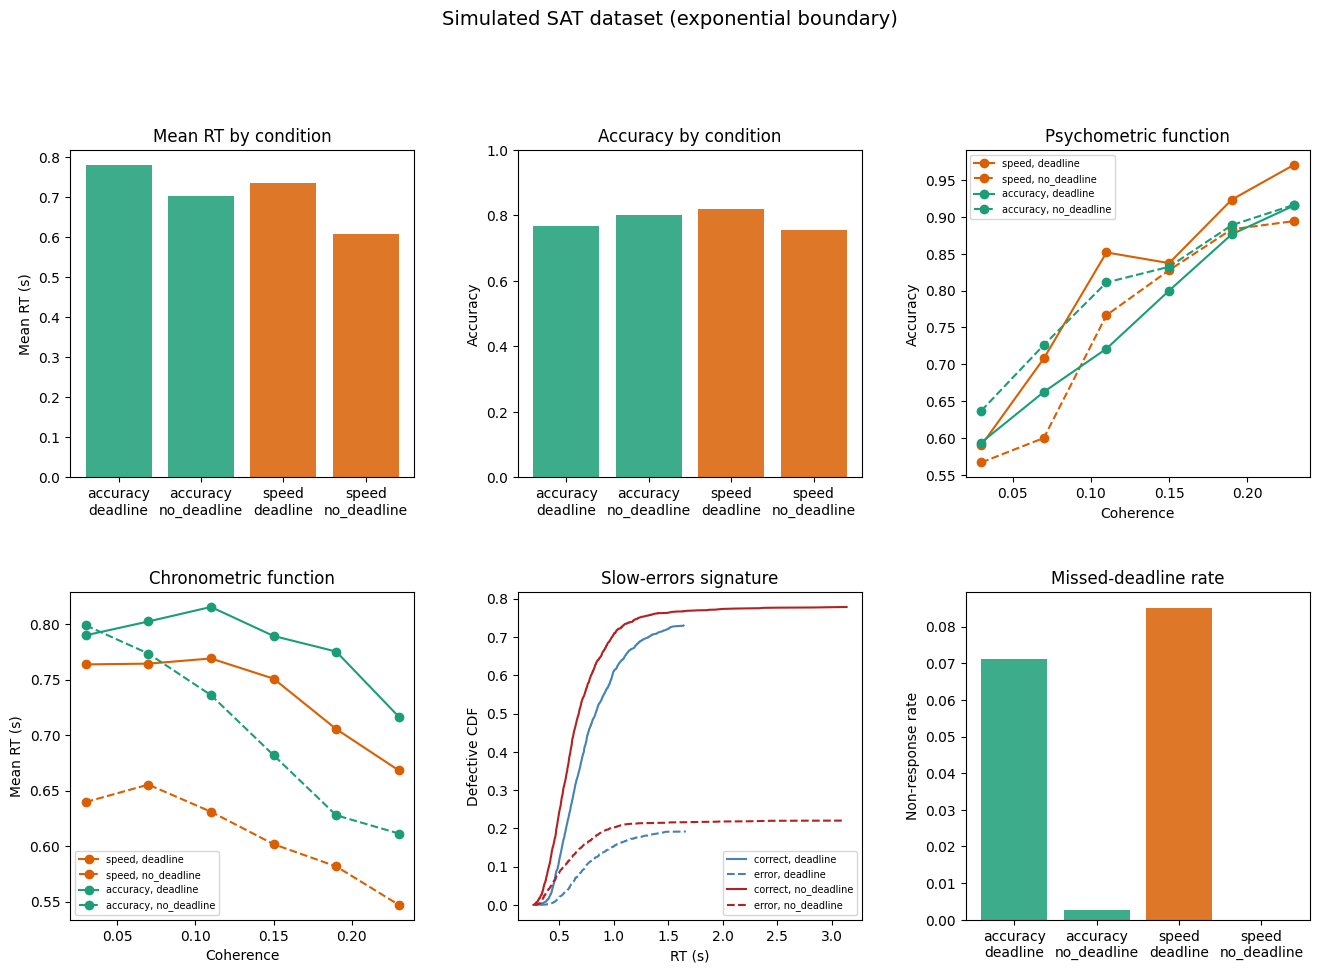

In [ ]:
true_params = []
for model in ["fixed", "linear", "exponential", "sigmoid"]:
    df, params_df = simulate_full_dataset(model=model, n_participants=6, n_trials_per_cell=30, seed=1)
    df.to_csv(f"../data/simulated_data_{model}.csv", index=False)
    params_df["model"] = model
    true_params.append(params_df)

    if model == "exponential":
        plot_insight_summary(df, title=f"Simulated SAT dataset ({model} boundary)")

true_params_df = pd.concat(true_params, ignore_index=True)
true_params_df.to_csv("../data/true_params.csv", index=False)